# Dataset-Independent Synthetic Data Generation & Quality Evaluation

This notebook accepts **any tabular CSV dataset** and detects its columns and data types automatically. It does not require fixed fields such as `age`, `gender`, or `sentiment`.

## What it does
1. Upload any CSV.
2. Profile columns and infer types (numeric, categorical, datetime, identifier, or high-cardinality text).
3. Generate a synthetic dataset dynamically.
4. Validate schema and missing-value consistency.
5. Scan for common PII patterns and sensitive column names.
6. Compare real and synthetic distributions.
7. Check exact record overlap as a basic privacy screen.
8. Optionally compare group representation and an outcome column for bias.


**Theory**:

Synthetic Data Generation using Agentic AI involves creating artificial datasets that resemble real-world data while reducing dependence on sensitive or limited real data. The system uses specialized agents to perform different tasks, including dataset profiling, synthetic data generation, schema validation, PII detection, and statistical distribution comparison.

The generated data is evaluated using statistical techniques such as the Kolmogorov-Smirnov (KS) test and Total Variation Distance (TVD) to measure similarity with the original dataset. Privacy risk is assessed through record-overlap checks, while bias evaluation compares demographic representation and outcomes across groups.

The system supports different CSV datasets by automatically detecting column names and data types, making it adaptable to domains such as healthcare, education, customer analytics, and social media.

In [1]:
!pip -q install pandas numpy scipy matplotlib

## 1. Imports

In [2]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

## 2. Upload any CSV dataset

Upload a CSV file. The notebook will inspect its column names and contents rather than expecting a fixed schema.

In [3]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise ValueError("Please upload a CSV file and rerun this cell.")

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print(f"Loaded: {filename}")
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
display(df.head())

Saving social_media_analytics_dataset.csv to social_media_analytics_dataset.csv
Loaded: social_media_analytics_dataset.csv
Rows: 2,000 | Columns: 11


,user_id,age,gender,region,platform,followers,posts_per_week,sentiment,engagement_rate,topic,account_type
0,USR_00001,54,Female,India,TikTok,2550,8,Positive,0.1835,Technology,Personal
1,USR_00002,25,Male,India,Facebook,871,5,Neutral,0.1692,Food,Personal
2,USR_00003,19,Female,India,Instagram,1120,4,Negative,0.1693,Sports,Personal
3,USR_00004,45,Female,India,LinkedIn,7089,8,Positive,0.0683,Entertainment,Personal
4,USR_00005,33,Female,USA,Twitter,13238,7,Neutral,0.1764,Education,Creator


## 3. Agent 1 — Dataset Profiling Agent

The profiler infers each column's role from its values:
- **numeric**: numerical measurements
- **datetime**: date/time-like values
- **identifier**: likely ID/key columns
- **categorical**: repeated labels or categories
- **text_high_cardinality**: mostly unique text/free-text fields

Some columns are ambiguous. Review the profile before generating data.

In [4]:
def infer_column_type(series, column_name):
    name = str(column_name).lower()
    non_null = series.dropna()
    if len(non_null) == 0:
        return "empty"

    id_name_hints = ["id", "uuid", "key", "account_no", "record_no"]
    if any(hint in name for hint in id_name_hints):
        return "identifier"

    # Detect datetime only when parsing succeeds for most non-null values.
    if not pd.api.types.is_numeric_dtype(series):
        try:
            parsed = pd.to_datetime(non_null, errors="coerce")
            if parsed.notna().mean() >= 0.85:
                return "datetime"
        except Exception:
            pass

    if pd.api.types.is_bool_dtype(series):
        return "categorical"

    if pd.api.types.is_numeric_dtype(series):
        unique_ratio = non_null.nunique() / max(len(non_null), 1)
        if unique_ratio > 0.98 and non_null.nunique() > 20:
            return "identifier"
        return "numeric"

    unique_count = non_null.nunique()
    unique_ratio = unique_count / max(len(non_null), 1)

    if unique_count <= 30 or unique_ratio <= 0.10:
        return "categorical"

    return "text_high_cardinality"


def profile_dataset(data):
    rows = []
    for col in data.columns:
        s = data[col]
        inferred = infer_column_type(s, col)
        examples = s.dropna().astype(str).head(3).tolist()
        rows.append({
            "column": col,
            "pandas_dtype": str(s.dtype),
            "inferred_type": inferred,
            "missing_count": int(s.isna().sum()),
            "missing_percent": round(float(s.isna().mean() * 100), 2),
            "unique_values": int(s.nunique(dropna=True)),
            "example_values": examples
        })
    return pd.DataFrame(rows)

profile = profile_dataset(df)
display(profile)
print("\nDetected types:")
display(profile["inferred_type"].value_counts().rename_axis("type").to_frame("columns"))

/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent

,column,pandas_dtype,inferred_type,missing_count,missing_percent,unique_values,example_values
0,user_id,object,identifier,0,0.0,2000,"[USR_00001, USR_00002, USR_00003]"
1,age,int64,numeric,0,0.0,43,"[54, 25, 19]"
2,gender,object,categorical,0,0.0,3,"[Female, Male, Female]"
3,region,object,categorical,0,0.0,5,"[India, India, India]"
4,platform,object,categorical,0,0.0,5,"[TikTok, Facebook, Instagram]"
5,followers,int64,numeric,0,0.0,1561,"[2550, 871, 1120]"
6,posts_per_week,int64,numeric,0,0.0,15,"[8, 5, 4]"
7,sentiment,object,categorical,0,0.0,3,"[Positive, Neutral, Negative]"
8,engagement_rate,float64,numeric,0,0.0,1338,"[0.1835, 0.1692, 0.1693]"
9,topic,object,categorical,0,0.0,7,"[Technology, Food, Sports]"



Detected types:


,columns
type,
categorical,6
numeric,4
identifier,1


## 4. Agent 2 — Dynamic Synthetic Data Generation Agent

The generator uses the inferred type of each column:
- Numeric: resamples observed values (preserves marginal values, not relationships).
- Categorical: resamples observed categories.
- Datetime: resamples observed dates.
- Identifier: creates new synthetic identifiers.
- High-cardinality text: creates placeholders to avoid copying potentially identifying free text.
- Empty: remains missing.

This creates a generic baseline for arbitrary tabular data. It does **not** create semantically realistic healthcare/customer/etc. records.

In [5]:
def generate_synthetic_dataset(data, profile_table, n_rows=None, seed=42):
    local_rng = np.random.default_rng(seed)
    if n_rows is None:
        n_rows = len(data)

    generated = pd.DataFrame(index=range(n_rows))

    for _, info in profile_table.iterrows():
        col = info["column"]
        kind = info["inferred_type"]
        s = data[col]
        non_null = s.dropna()

        if kind == "identifier":
            generated[col] = [f"SYN_{col}_{i+1:06d}" for i in range(n_rows)]

        elif kind == "numeric":
            if len(non_null):
                values = pd.to_numeric(non_null, errors="coerce").dropna().to_numpy()
                generated[col] = local_rng.choice(values, size=n_rows, replace=True)
            else:
                generated[col] = np.nan

        elif kind == "categorical":
            if len(non_null):
                values = non_null.astype(str).to_numpy()
                generated[col] = local_rng.choice(values, size=n_rows, replace=True)
            else:
                generated[col] = np.nan

        elif kind == "datetime":
            parsed = pd.to_datetime(non_null, errors="coerce").dropna()
            if len(parsed):
                chosen = local_rng.choice(parsed.astype("int64").to_numpy(), size=n_rows, replace=True)
                generated[col] = pd.to_datetime(chosen)
            else:
                generated[col] = pd.NaT

        elif kind == "text_high_cardinality":
            generated[col] = [f"SYNTHETIC_TEXT_{i+1:06d}" for i in range(n_rows)]

        else:
            generated[col] = np.nan

        # Preserve the approximate missing-value rate of the original column.
        missing_rate = float(s.isna().mean())
        if missing_rate > 0:
            mask = local_rng.random(n_rows) < missing_rate
            generated.loc[mask, col] = np.nan

    return generated[data.columns]


N_SYNTHETIC = len(df)  # Change this number if you want a different synthetic dataset size.
synthetic_df = generate_synthetic_dataset(df, profile, n_rows=N_SYNTHETIC, seed=SEED)

print("Synthetic dataset shape:", synthetic_df.shape)
display(synthetic_df.head())

Synthetic dataset shape: (2000, 11)


,user_id,age,gender,region,platform,followers,posts_per_week,sentiment,engagement_rate,topic,account_type
0,SYN_user_id_000001,42,Male,India,Facebook,711,5,Positive,0.1622,Fashion,Personal
1,SYN_user_id_000002,38,Male,Canada,TikTok,1602,4,Positive,0.0610,Travel,Personal
2,SYN_user_id_000003,57,Female,India,Twitter,322,10,Positive,0.1158,Fashion,Personal
3,SYN_user_id_000004,35,Male,USA,Instagram,5703,10,Positive,0.2072,Entertainment,Creator
4,SYN_user_id_000005,18,Female,Canada,Instagram,1539,3,Positive,0.0674,Technology,Business


## 5. Agent 3 — Dynamic Schema Validation Agent

Checks that the synthetic dataset has the same columns and order, compatible inferred types, and a missing-value rate close to the reference. It also reports missing values for every column.

In [6]:
def validate_dynamic_schema(real, synthetic, real_profile, synthetic_profile):
    same_columns = list(real.columns) == list(synthetic.columns)
    real_types = dict(zip(real_profile["column"], real_profile["inferred_type"]))
    synth_types = dict(zip(synthetic_profile["column"], synthetic_profile["inferred_type"]))

    type_comparison = []
    for col in real.columns:
        type_comparison.append({
            "column": col,
            "real_type": real_types.get(col),
            "synthetic_type": synth_types.get(col),
            "type_match": real_types.get(col) == synth_types.get(col),
            "real_missing_%": round(real[col].isna().mean() * 100, 2),
            "synthetic_missing_%": round(synthetic[col].isna().mean() * 100, 2)
        })

    details = pd.DataFrame(type_comparison)
    result = {
        "same_columns_and_order": same_columns,
        "all_inferred_types_match": bool(details["type_match"].all()),
        "missing_value_counts": synthetic.isna().sum().to_dict(),
        "column_checks": details
    }
    return result

synthetic_profile = profile_dataset(synthetic_df)
schema_result = validate_dynamic_schema(df, synthetic_df, profile, synthetic_profile)

print("Same columns and order:", schema_result["same_columns_and_order"])
print("All inferred types match:", schema_result["all_inferred_types_match"])
display(schema_result["column_checks"])

Same columns and order: True
All inferred types match: True


/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent

,column,real_type,synthetic_type,type_match,real_missing_%,synthetic_missing_%
0,user_id,identifier,identifier,True,0.0,0.0
1,age,numeric,numeric,True,0.0,0.0
2,gender,categorical,categorical,True,0.0,0.0
3,region,categorical,categorical,True,0.0,0.0
4,platform,categorical,categorical,True,0.0,0.0
5,followers,numeric,numeric,True,0.0,0.0
6,posts_per_week,numeric,numeric,True,0.0,0.0
7,sentiment,categorical,categorical,True,0.0,0.0
8,engagement_rate,numeric,numeric,True,0.0,0.0
9,topic,categorical,categorical,True,0.0,0.0


## 6. Agent 4 — Generic PII Detection Agent

Checks common email, phone, and Aadhaar-like patterns in string values. It also flags columns whose names suggest sensitive information. This is a heuristic scanner; it may miss PII or flag non-PII values.

In [7]:
PII_PATTERNS = {
    "email": re.compile(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"),
    "phone": re.compile(r"(?<!\d)(?:\+?\d{1,3}[- ]?)?[6-9]\d{9}(?!\d)"),
    "aadhaar_like": re.compile(r"(?<!\d)\d{4}[ -]?\d{4}[ -]?\d{4}(?!\d)")
}
SENSITIVE_NAME_HINTS = ["name", "email", "phone", "mobile", "address", "aadhaar", "ssn", "passport", "patient"]

def detect_pii_generic(data):
    findings = []
    for col in data.columns:
        col_lower = str(col).lower()
        if any(hint in col_lower for hint in SENSITIVE_NAME_HINTS):
            findings.append({"column": col, "finding": "Sensitive-looking column name"})
        if data[col].dtype == "object" or pd.api.types.is_string_dtype(data[col]):
            for value in data[col].dropna().astype(str):
                for label, pattern in PII_PATTERNS.items():
                    if pattern.search(value):
                        findings.append({"column": col, "finding": f"Pattern detected: {label}"})
                        break
    findings_df = pd.DataFrame(findings, columns=["column", "finding"]).drop_duplicates()
    return findings_df

pii_findings = detect_pii_generic(synthetic_df)
print("Potential PII findings:", len(pii_findings))
display(pii_findings.head(50))

Potential PII findings: 0


,column,finding


## 7. Agent 5 — Dynamic Distribution Evaluation Agent

Compares all supported shared columns without requiring specific names:
- Numeric columns: KS statistic.
- Categorical and datetime columns: Total Variation Distance (TVD).
- Identifier and high-cardinality text columns: skipped because their generated values are intentionally new placeholders.

Lower distances indicate closer marginal distributions. These metrics do not test relationships between columns.

,column,type,metric,score,p_value
0,user_id,identifier,Skipped,NaN,NaN
1,age,numeric,KS statistic,0.0180,0.902355
2,gender,categorical,TVD,0.0120,NaN
3,region,categorical,TVD,0.0060,NaN
4,platform,categorical,TVD,0.0190,NaN
5,followers,numeric,KS statistic,0.0270,0.459637
6,posts_per_week,numeric,KS statistic,0.0090,0.999998
7,sentiment,categorical,TVD,0.0095,NaN
8,engagement_rate,numeric,KS statistic,0.0210,0.770029
9,topic,categorical,TVD,0.0180,NaN


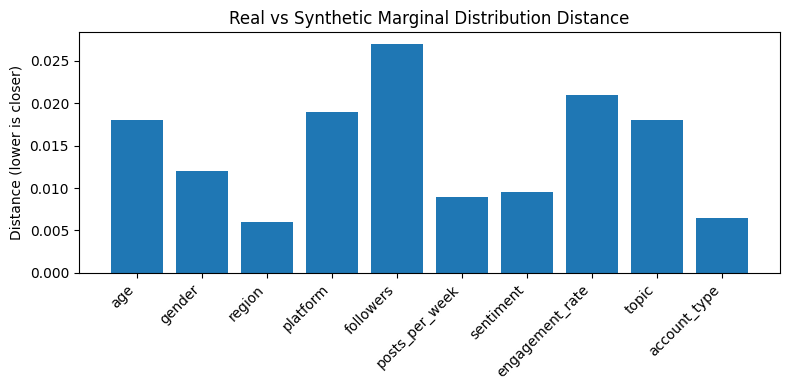

In [8]:
def tvd_from_series(real_series, synthetic_series):
    r = real_series.dropna().astype(str).value_counts(normalize=True)
    s = synthetic_series.dropna().astype(str).value_counts(normalize=True)
    categories = r.index.union(s.index)
    return 0.5 * sum(abs(r.get(x, 0) - s.get(x, 0)) for x in categories)


def compare_all_distributions(real, synthetic, profile_table):
    rows = []
    for _, info in profile_table.iterrows():
        col, kind = info["column"], info["inferred_type"]
        if kind == "numeric":
            r = pd.to_numeric(real[col], errors="coerce").dropna()
            s = pd.to_numeric(synthetic[col], errors="coerce").dropna()
            if len(r) and len(s):
                stat, pvalue = ks_2samp(r, s)
                rows.append({"column": col, "type": kind, "metric": "KS statistic",
                             "score": float(stat), "p_value": float(pvalue)})
        elif kind in ["categorical", "datetime"]:
            score = tvd_from_series(real[col], synthetic[col])
            rows.append({"column": col, "type": kind, "metric": "TVD",
                         "score": float(score), "p_value": np.nan})
        else:
            rows.append({"column": col, "type": kind, "metric": "Skipped",
                         "score": np.nan, "p_value": np.nan})
    return pd.DataFrame(rows)

distribution_results = compare_all_distributions(df, synthetic_df, profile)
display(distribution_results)

plot_data = distribution_results.dropna(subset=["score"])
if not plot_data.empty:
    plt.figure(figsize=(max(8, len(plot_data) * 0.8), 4))
    plt.bar(plot_data["column"], plot_data["score"])
    plt.title("Real vs Synthetic Marginal Distribution Distance")
    plt.ylabel("Distance (lower is closer)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 8. Agent 6 — Basic Privacy-Risk Screening

Checks exact full-row overlap across shared columns, excluding columns inferred as identifiers. This is only a basic overlap screen and not a formal privacy test.

In [9]:
def exact_overlap_screen(real, synthetic, profile_table):
    excluded = set(profile_table.loc[
        profile_table["inferred_type"].isin(["identifier", "text_high_cardinality"]),
        "column"
    ])
    common = [c for c in real.columns if c in synthetic.columns and c not in excluded]
    if not common:
        return {"columns_compared": [], "exact_matches": None, "match_rate_%": None}

    real_rows = set(map(tuple, real[common].fillna("<NA>").astype(str).to_numpy()))
    synth_rows = list(map(tuple, synthetic[common].fillna("<NA>").astype(str).to_numpy()))
    matches = sum(row in real_rows for row in synth_rows)
    rate = matches / len(synth_rows) * 100 if synth_rows else 0

    return {
        "columns_compared": common,
        "exact_matches": int(matches),
        "match_rate_%": round(rate, 2),
        "interpretation": "Review overlap; this is not a privacy guarantee."
    }

privacy_result = exact_overlap_screen(df, synthetic_df, profile)
print(privacy_result)

{'columns_compared': ['age', 'gender', 'region', 'platform', 'followers', 'posts_per_week', 'sentiment', 'engagement_rate', 'topic', 'account_type'], 'exact_matches': 0, 'match_rate_%': 0.0, 'interpretation': 'Review overlap; this is not a privacy guarantee.'}


## 9. Agent 7 — Optional Bias Comparison

Because datasets use different column names, select a **group column** (for example, gender, region, age_group) and optionally an **outcome column** (for example, approval, diagnosis, sentiment, result). The notebook will compare group representation and outcome rates where possible.

This is a descriptive fairness check, not a complete fairness audit.

In [10]:
# Select columns from the uploaded dataset. Set either to None to skip that comparison.
available_cols = list(df.columns)
print("Available columns:", available_cols)

group_col = input("Enter group/demographic column name (or press Enter to skip): ").strip() or None
outcome_col = input("Enter binary/categorical outcome column name (or press Enter to skip outcome rates): ").strip() or None

def compare_bias(real, synthetic, group_col=None, outcome_col=None):
    if group_col is None or group_col not in real.columns or group_col not in synthetic.columns:
        print("Bias comparison skipped: valid group column not selected.")
        return pd.DataFrame()

    rows = []
    for label, data in [("Real", real), ("Synthetic", synthetic)]:
        group_series = data[group_col]
        valid = group_series.notna()
        total = int(valid.sum())
        for group in group_series[valid].astype(str).unique():
            mask = valid & (group_series.astype(str) == group)
            row = {
                "dataset": label,
                "group": group,
                "representation_%": (mask.sum() / total * 100) if total else np.nan
            }
            if outcome_col and outcome_col in data.columns:
                outcome = data.loc[mask, outcome_col].dropna()
                # For categorical outcomes, show the rate of the most frequent non-null category.
                if len(outcome):
                    top_category = outcome.astype(str).value_counts().idxmax()
                    row["most_common_outcome"] = top_category
                    row["most_common_outcome_rate_%"] = (
                        (outcome.astype(str) == top_category).mean() * 100
                    )
            rows.append(row)

    return pd.DataFrame(rows)

bias_results = compare_bias(df, synthetic_df, group_col, outcome_col)
display(bias_results)

Available columns: ['user_id', 'age', 'gender', 'region', 'platform', 'followers', 'posts_per_week', 'sentiment', 'engagement_rate', 'topic', 'account_type']
Enter group/demographic column name (or press Enter to skip): gender
Enter binary/categorical outcome column name (or press Enter to skip outcome rates): sentiment


,dataset,group,representation_%,most_common_outcome,most_common_outcome_rate_%
0,Real,Female,43.6,Positive,53.440367
1,Real,Male,48.2,Positive,52.904564
2,Real,Other,8.2,Positive,51.219512
3,Synthetic,Male,47.0,Positive,54.255319
4,Synthetic,Female,44.8,Positive,52.120536
5,Synthetic,Other,8.2,Positive,55.487805


## 10. Orchestrator — Run the complete workflow

This cell runs profiling, generation, validation, PII scanning, distribution comparison, privacy screening, and optional bias comparison in sequence. The notebook is a deterministic pipeline; an autonomous LLM controller is not included.

In [11]:
def run_pipeline(data, n_rows=None, seed=42):
    prof = profile_dataset(data)
    synth = generate_synthetic_dataset(data, prof, n_rows=n_rows, seed=seed)
    synth_prof = profile_dataset(synth)
    return {
        "profile": prof,
        "synthetic": synth,
        "schema": validate_dynamic_schema(data, synth, prof, synth_prof),
        "pii": detect_pii_generic(synth),
        "distribution": compare_all_distributions(data, synth, prof),
        "privacy": exact_overlap_screen(data, synth, prof)
    }

results = run_pipeline(df, n_rows=N_SYNTHETIC, seed=SEED)

print("PIPELINE COMPLETED")
print("Rows generated:", len(results["synthetic"]))
print("Schema columns/order match:", results["schema"]["same_columns_and_order"])
print("Potential PII findings:", len(results["pii"]))
print("Distribution columns evaluated:", (results["distribution"]["metric"] != "Skipped").sum())
print("Exact overlap screen:", results["privacy"])

PIPELINE COMPLETED
Rows generated: 2000
Schema columns/order match: True
Potential PII findings: 0
Distribution columns evaluated: 10
Exact overlap screen: {'columns_compared': ['age', 'gender', 'region', 'platform', 'followers', 'posts_per_week', 'sentiment', 'engagement_rate', 'topic', 'account_type'], 'exact_matches': 0, 'match_rate_%': 0.0, 'interpretation': 'Review overlap; this is not a privacy guarantee.'}


/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(non_null, errors="coerce")
/tmp/ipykernel_740/3816258984.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent

## 11. Download generated dataset and reports

In [12]:
results["synthetic"].to_csv("synthetic_dataset.csv", index=False)
results["profile"].to_csv("dataset_profile.csv", index=False)
results["distribution"].to_csv("distribution_evaluation.csv", index=False)
results["pii"].to_csv("pii_findings.csv", index=False)
results["schema"]["column_checks"].to_csv("schema_validation.csv", index=False)
if not bias_results.empty:
    bias_results.to_csv("bias_comparison.csv", index=False)

print("Created output files:")
for name in ["synthetic_dataset.csv", "dataset_profile.csv",
             "distribution_evaluation.csv", "pii_findings.csv",
             "schema_validation.csv"]:
    print("-", name)

from google.colab import files
files.download("synthetic_dataset.csv")
files.download("dataset_profile.csv")
files.download("distribution_evaluation.csv")
files.download("pii_findings.csv")
files.download("schema_validation.csv")
if not bias_results.empty:
    files.download("bias_comparison.csv")

Created output files:
- synthetic_dataset.csv
- dataset_profile.csv
- distribution_evaluation.csv
- pii_findings.csv
- schema_validation.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Interpretation and conclusion

- The profiler adapts to the uploaded CSV's column names and inferred types.
- The generator produces a synthetic table with the same schema and row count (or requested row count).
- Schema checks compare columns, inferred types, and missingness.
- PII checks use common patterns and sensitive-looking column names.
- Distribution evaluation compares marginal numerical and categorical distributions.
- Privacy screening measures exact overlap on selected non-ID columns.
- Bias comparison is configurable by the user by selecting group and outcome columns.

### Conclusion
This notebook provides a dataset-independent baseline for synthetic tabular data generation and quality evaluation. It can process different CSV schemas without hardcoded domain-specific column names. However, column-wise sampling does not preserve correlations or complex semantics. For higher-quality synthetic data, the next step is to use a tabular synthesis model (such as CTGAN/SDV), evaluate relationships and downstream model utility, and apply stronger privacy and fairness tests.